# QML — Week 1: Qubits, State Vectors, Measurement

**Goal of the week:** be able to read and write a quantum state as a vector, predict measurement statistics, and build multi-qubit states — using only `numpy`, then confirm with PennyLane.

| # | Topic | Time |
|---|-------|------|
| 1 | Classical bit vs. qubit | 30 min |
| 2 | State vectors in numpy | 45 min |
| 3 | Measurement and the Born rule | 1 h |
| 4 | Global vs. relative phase | 45 min |
| 5 | Multiple qubits and the tensor product | 1 h |
| 6 | The exponential state space | 30 min |
| 7 | Hands-on with PennyLane | 1 h |
| 8 | Exercises | 1–2 h |
| 9 | Cheat sheet and what's next | 15 min |

**Prerequisites:** linear algebra (vectors, norms, matrix products), basic probability. You already have these from ML.

In [1]:
# pip install numpy matplotlib pennylane
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

---
## 1. Classical bit vs. qubit

### 1.1 What a qubit is

A classical bit is either `0` or `1`. A qubit's state is a **unit vector in a 2-dimensional complex space**:

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1$$

- $\alpha, \beta \in \mathbb{C}$ are **amplitudes** — not probabilities.
- The constraint says the vector has L2 norm 1.

**ML analogy.** Think of a 2-class softmax output, with two differences:
1. Probabilities come from *squared amplitudes*, not from exp-normalization.
2. Amplitudes are signed/complex, so they can **interfere** (cancel or reinforce). Probabilities cannot. Interference is where quantum speedups come from.

| | Classical bit | Qubit |
|---|---|---|
| State | `0` or `1` | $\alpha\lvert0\rangle+\beta\lvert1\rangle$ |
| Description size | 1 bit | 2 complex numbers (1 constraint) |
| Reading it out | exact | probabilistic, destroys the state |

### 1.2 Visualizing a qubit

A classical bit is two points. A qubit is a **point on a sphere** (the Bloch sphere): any pure state is a unit vector $(x, y, z)$ with

$$x = 2\,\mathrm{Re}(\alpha^*\beta), \qquad y = 2\,\mathrm{Im}(\alpha^*\beta), \qquad z = |\alpha|^2 - |\beta|^2$$

- **Poles** $(z=\pm1)$: the classical bits $|0\rangle$ (north) and $|1\rangle$ (south).
- **Equator** $(z=0)$: equal superpositions, differing only in relative phase ($|+\rangle$ on $+x$, $|-\rangle$ on $-x$).
- **Height $z$** sets the measurement probabilities: $P(0) = (1+z)/2$.
- **Angle around the $z$-axis** is the relative phase — invisible to a computational-basis measurement.

Below, each state is shown twice: on the Bloch sphere (the *state*) and as a bar chart (what a *measurement* reveals).

In [ ]:
def bloch_vector(psi):
    a, b = psi
    return np.array([2 * (np.conj(a) * b).real,
                     2 * (np.conj(a) * b).imag,
                     abs(a) ** 2 - abs(b) ** 2])

def draw_bloch(ax, psi, title=""):
    u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                      color="lightgray", alpha=0.35, linewidth=0.5)
    for d in np.eye(3):                                   # x, y, z axes
        ax.plot(*zip(-d, d), color="gray", linewidth=0.8)
    for pos, lab in [((0, 0, 1.25), "|0>"), ((0, 0, -1.3), "|1>"),
                     ((1.3, 0, 0), "|+>"), ((-1.35, 0, 0), "|->")]:
        ax.text(*pos, lab, ha="center", va="center")
    x, y, z = bloch_vector(psi)
    ax.quiver(0, 0, 0, x, y, z, color="crimson", linewidth=2.5, arrow_length_ratio=0.15)
    ax.scatter([x], [y], [z], color="crimson", s=30)
    ax.set_title(title)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()

def show_qubit(states):
    # One column per state: Bloch sphere on top, measurement probabilities below.
    fig = plt.figure(figsize=(3.6 * len(states), 6.4))
    gs = fig.add_gridspec(2, len(states), height_ratios=[2.2, 1])
    for i, (name, psi) in enumerate(states.items()):
        draw_bloch(fig.add_subplot(2, len(states), i + 1, projection="3d"), psi, name)
        ax = fig.add_subplot(gs[1, i])
        ax.bar(["P(0)", "P(1)"], np.abs(psi) ** 2, color=["tab:blue", "tab:orange"])
        ax.set_ylim(0, 1)
        if i: ax.set_yticklabels([])
    fig.tight_layout(); plt.show()

s2 = 1 / np.sqrt(2)
show_qubit({
    "|0>": np.array([1, 0], dtype=complex),
    "|1>": np.array([0, 1], dtype=complex),
    "|+>": np.array([s2, s2], dtype=complex),
    "|->": np.array([s2, -s2], dtype=complex),
})

Notice that $|+\rangle$ and $|-\rangle$ have **identical bar charts** but sit at opposite points on the sphere — the sphere shows the phase that a single measurement hides. We come back to this in section 4.

A state with unequal amplitudes and a non-trivial phase, e.g. $\tfrac{3}{5}|0\rangle + \tfrac{4}{5}e^{i\pi/3}|1\rangle$:

In [ ]:
show_qubit({"3/5|0> + 4/5 e^{i pi/3}|1>": np.array([3/5, 4/5 * np.exp(1j * np.pi / 3)])})

---
## 2. State vectors in numpy

The basis states are the standard basis vectors:

$$|0\rangle = \begin{pmatrix}1\\0\end{pmatrix}, \qquad |1\rangle = \begin{pmatrix}0\\1\end{pmatrix}$$

In [2]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)

def is_valid_state(psi, tol=1e-9):
    return np.isclose(np.linalg.norm(psi), 1.0, atol=tol)

psi = (3/5) * ket0 + (4/5) * ket1
print("psi =", psi)
print("valid?", is_valid_state(psi))
print("bad state valid?", is_valid_state(np.array([1, 1], dtype=complex)))

psi = [0.6+0.j 0.8+0.j]
valid? True
bad state valid? False


**Bloch sphere (preview).** Any single-qubit state can be written, up to global phase, as

$$|\psi\rangle = \cos\tfrac{\theta}{2}|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}|1\rangle$$

so it is fully described by two angles $(\theta, \varphi)$ — a point on a sphere. $|0\rangle$ is the north pole, $|1\rangle$ the south pole. We will rotate these points with gates in Week 2.

In [3]:
def bloch_state(theta, phi):
    return np.array([np.cos(theta/2), np.exp(1j*phi) * np.sin(theta/2)])

for name, (t, p) in {"|0>": (0, 0), "|1>": (np.pi, 0), "|+>": (np.pi/2, 0), "|->": (np.pi/2, np.pi)}.items():
    s = bloch_state(t, p)
    print(f"{name:4s} -> {s}   valid={is_valid_state(s)}")

|0>  -> [1.+0.j 0.+0.j]   valid=True
|1>  -> [0.+0.j 1.+0.j]   valid=True
|+>  -> [0.7071+0.j 0.7071+0.j]   valid=True
|->  -> [ 0.7071+0.j -0.7071+0.j]   valid=True


---
## 3. Measurement and the Born rule

Measuring in the computational basis returns one outcome:

$$P(0) = |\alpha|^2, \qquad P(1) = |\beta|^2$$

and the state **collapses** to the observed basis state. You never see $\alpha,\beta$ directly.

**Consequences for QML**
- A model output is a *statistical estimate*: run the circuit many times (**shots**) and average.
- Estimator noise falls as $1/\sqrt{\text{shots}}$, exactly like Monte Carlo.

In [4]:
def probabilities(psi):
    return np.abs(psi) ** 2

def measure(psi, shots=1000):
    p = probabilities(psi)
    p = p / p.sum()
    outcomes = rng.choice(len(psi), size=shots, p=p)
    return np.bincount(outcomes, minlength=len(psi)) / shots

psi = (3/5) * ket0 + (4/5) * ket1
print("exact   :", probabilities(psi))
print("100 shots:", measure(psi, 100))
print("100k shots:", measure(psi, 100_000))

exact   : [0.36 0.64]
100 shots: [0.34 0.66]
100k shots: [0.3589 0.6411]


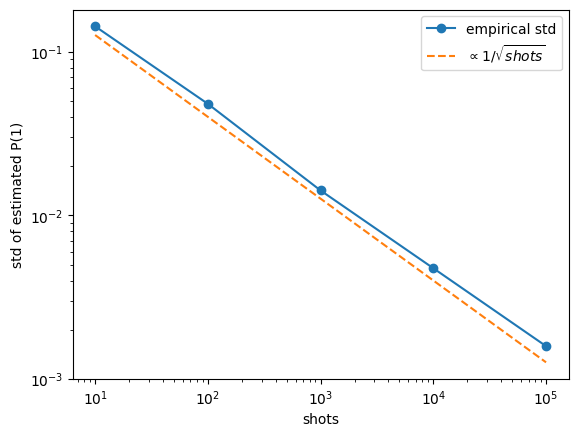

In [5]:
# Estimator noise ~ 1/sqrt(shots)
shots_list = [10, 100, 1_000, 10_000, 100_000]
errors = []
for s in shots_list:
    est = [measure(psi, s)[1] for _ in range(200)]
    errors.append(np.std(est))

plt.loglog(shots_list, errors, "o-", label="empirical std")
plt.loglog(shots_list, 0.4 / np.sqrt(shots_list), "--", label=r"$\propto 1/\sqrt{shots}$")
plt.xlabel("shots"); plt.ylabel("std of estimated P(1)"); plt.legend(); plt.show()

---
## 4. Global vs. relative phase

Compare two states:

$$|+\rangle = \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle), \qquad |-\rangle = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle)$$

Both give 50/50 under computational-basis measurement, yet they are **different states**. The sign is a *relative phase*, invisible to this measurement but visible after a gate that makes the amplitudes interfere (the Hadamard, in Week 2).

- **Global phase** ($e^{i\gamma}$ multiplying the whole vector): physically unobservable.
- **Relative phase** (between $\alpha$ and $\beta$): observable through interference.

In [6]:
plus  = (ket0 + ket1) / np.sqrt(2)
minus = (ket0 - ket1) / np.sqrt(2)

print("P(|+>)  =", probabilities(plus))
print("P(|->)  =", probabilities(minus))

# Global phase changes nothing observable
g = np.exp(1j * 1.234) * plus
print("P(global-phase |+>) =", probabilities(g))

# But |+> and |-> are orthogonal -> perfectly distinguishable in the right basis
print("<+|-> =", np.vdot(plus, minus))

P(|+>)  = [0.5 0.5]
P(|->)  = [0.5 0.5]
P(global-phase |+>) = [0.5 0.5]
<+|-> = (-2.2371143170757382e-17+0j)


---
## 5. Multiple qubits and the tensor product

Two qubits live in the **tensor (Kronecker) product** of two 2-d spaces — a 4-d space:

$$|0\rangle\otimes|1\rangle = |01\rangle = (0,1,0,0)^T$$

General 2-qubit state: $\;a|00\rangle + b|01\rangle + c|10\rangle + d|11\rangle$ with $\sum|\cdot|^2 = 1$.

**Product states vs. entangled states**
- *Product state*: can be written as $|\psi_A\rangle\otimes|\psi_B\rangle$.
- *Entangled state*: cannot. Example, the Bell state $\tfrac{1}{\sqrt2}(|00\rangle+|11\rangle)$.

ML analogy: a product state is like a *rank-1* joint distribution (independent features); an entangled state carries correlations that no product of marginals can reproduce.

In [7]:
ket00 = np.kron(ket0, ket0)
ket01 = np.kron(ket0, ket1)
print("|01> =", ket01.real)

# Product state: |+> ⊗ |0>
prod = np.kron(plus, ket0)
print("|+>⊗|0> =", prod)

# Bell state
bell = (np.kron(ket0, ket0) + np.kron(ket1, ket1)) / np.sqrt(2)
print("Bell =", bell)
print("P(bell) over 00,01,10,11 =", probabilities(bell))

|01> = [0. 1. 0. 0.]
|+>⊗|0> = [0.7071+0.j 0.    +0.j 0.7071+0.j 0.    +0.j]
Bell = [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
P(bell) over 00,01,10,11 = [0.5 0.  0.  0.5]


In [8]:
# Is a 2-qubit state a product state? Reshape to 2x2 and look at the singular values (Schmidt decomposition).
def schmidt_coeffs(psi):
    return np.linalg.svd(psi.reshape(2, 2), compute_uv=False)

print("product :", schmidt_coeffs(prod))   # one non-zero value  -> product
print("bell    :", schmidt_coeffs(bell))   # two equal values    -> maximally entangled

product : [1. 0.]
bell    : [0.7071 0.7071]


> **Why that works.** Reshaping the 4-vector into a 2×2 matrix $M$, a product state is exactly a *rank-1* matrix. The number of non-zero singular values (the Schmidt rank) measures entanglement — familiar SVD, new meaning.

---
## 6. The exponential state space

$n$ qubits $\Rightarrow$ $2^n$ amplitudes.

| qubits | amplitudes | memory (complex128) |
|---|---|---|
| 10 | 1,024 | 16 KB |
| 30 | ~10⁹ | 16 GB |
| 40 | ~10¹² | 16 TB |
| 50 | ~10¹⁵ | 16 PB |

This is why classical simulation breaks down around 40–50 qubits — and why people hope for quantum advantage. It is **not** a free lunch: measurement returns only $n$ classical bits per shot.

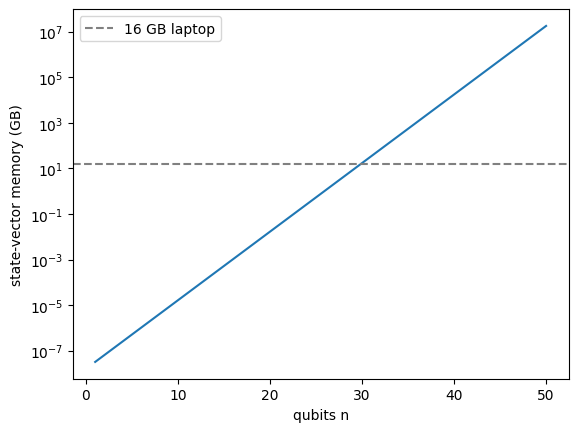

In [9]:
ns = np.arange(1, 51)
mem_bytes = (2.0 ** ns) * 16
plt.semilogy(ns, mem_bytes / 1e9)
plt.axhline(16, color="gray", ls="--", label="16 GB laptop")
plt.xlabel("qubits n"); plt.ylabel("state-vector memory (GB)"); plt.legend(); plt.show()

---
## 7. Hands-on with PennyLane

Confirm the numpy results with a real framework. We only use the Hadamard gate as a black box here — Week 2 explains gates properly.

In [10]:
import pennylane as qml

dev = qml.device("default.qubit", wires=1)

@qml.qnode(dev)
def plus_state():
    qml.Hadamard(wires=0)
    return qml.state()

print("state :", plus_state())

ModuleNotFoundError: No module named 'pennylane'

In [ ]:
# Finite shots -> sampling noise, just like our measure()
dev_shots = qml.device("default.qubit", wires=1, shots=1000)

@qml.qnode(dev_shots)
def plus_probs():
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)

for _ in range(3):
    print(plus_probs())

In [ ]:
# Bell state on 2 qubits
dev2 = qml.device("default.qubit", wires=2)

@qml.qnode(dev2)
def bell_circuit():
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    return qml.state()

print("PennyLane Bell:", bell_circuit())
print("our numpy Bell:", bell)

---
## 8. Exercises

Fill in the code cells. Try on paper first, then verify.

**Exercise 1 — validity.** Is $\tfrac{3}{5}|0\rangle + \tfrac{4}{5}|1\rangle$ a valid state? What are $P(0)$, $P(1)$?

In [ ]:
# TODO

**Exercise 2 — normalize.** Write `normalize(v)` and use it to turn $(1, 2i)$ into a valid state. Report $P(0)$, $P(1)$.

In [ ]:
def normalize(v):
    # TODO
    pass

**Exercise 3 — phase.** Show numerically that $|+\rangle$ and $|-\rangle$ have identical computational-basis statistics, but $\langle +|-\rangle = 0$. Why does that not contradict "identical statistics"?

In [ ]:
# TODO

**Exercise 4 — amplitudes of 3 qubits.** How many amplitudes describe a 3-qubit state? Build $|+\rangle^{\otimes 3}$ with `np.kron` and verify all 8 probabilities equal $1/8$.

In [ ]:
# TODO

**Exercise 5 — entanglement detector.** Use `schmidt_coeffs` on three random 2-qubit states: (a) a random product state, (b) the Bell state, (c) a random normalized 4-vector. Which are entangled?

In [ ]:
# TODO

**Exercise 6 (stretch) — shots.** How many shots do you need to estimate $P(1)$ of $\tfrac{3}{5}|0\rangle+\tfrac{4}{5}|1\rangle$ to within ±0.01 (one std)? Check by simulation.

In [ ]:
# TODO

---
## 9. Cheat sheet and what's next

| Concept | One-liner |
|---|---|
| Qubit state | unit vector $(\alpha,\beta)\in\mathbb{C}^2$ |
| Born rule | $P(i)=\lvert\text{amplitude}_i\rvert^2$ |
| Measurement | random, collapses state, $1/\sqrt{\text{shots}}$ noise |
| Global phase | unobservable |
| Relative phase | observable via interference |
| $n$ qubits | $2^n$-dim vector, built with `np.kron` |
| Entanglement | state is not a Kronecker product (Schmidt rank > 1) |

**Next — Week 2: Gates, simulation, hardware, advantage.** Gates are unitary matrices ($U^\dagger U = I$) — norm-preserving rotations. We cover X, Z, H, RX/RY/RZ and CNOT, see why $|+\rangle$ and $|-\rangle$ differ, build a state-vector simulator, look at how real quantum hardware executes circuits, and ask honestly where quantum beats classical.
